# Pre-trained Language Models: BERT & GPT

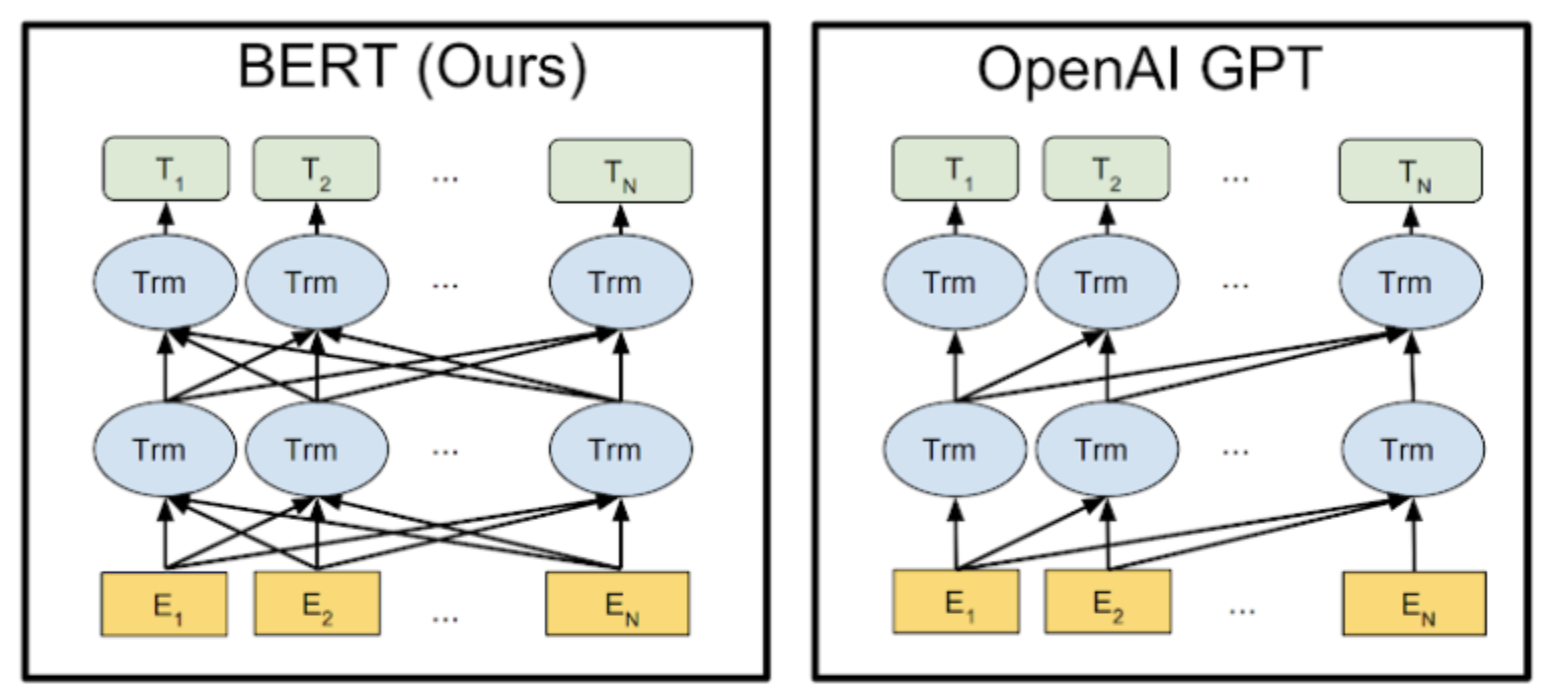

In [ ]:
%pip -q install "transformers==4.57.1"

In [ ]:
import re

import pandas as pd
import torch
from IPython.display import display
from transformers import (
    AutoModelForCausalLM,
    AutoModelForPreTraining,
    AutoTokenizer,
    set_seed,
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

## Task 1 · Static vs. Contextual Embeddings

Start with four sentences. Each one uses the word **bank**.

> 1. She put her money in the bank.
> 2. The bank gave him a loan.
> 3. We sat on the bank of the river.
> 4. He swam across the river to the bank.

BERT makes one vector for **bank** in each sentence. The table shows the cosine similarity between these vectors. Darker cells show higher similarity.

`layer` chooses where the vector comes from.

- **Layer 0** is the word embedding table. It is a static embedding: one word always gets the same vector, as in Word2Vec.
- **Layers 1–12** are BERT's Transformer layers. They give contextual embeddings.

In [ ]:
BERT_MODEL_ID = "google-bert/bert-base-uncased"
bert_tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL_ID)
bert = AutoModelForPreTraining.from_pretrained(BERT_MODEL_ID).to(device).eval()


def word_vector(sentence, word, layer, model, tokenizer):
    """Return the vector for `word` in `sentence` from one layer of `model`."""
    matches = list(re.finditer(rf"\b{re.escape(word)}\b", sentence, flags=re.IGNORECASE))
    if len(matches) != 1:
        raise ValueError(f'Use "{word}" exactly once in this sentence: {sentence}')
    if not 0 <= layer <= model.config.num_hidden_layers:
        raise ValueError(f"Choose a layer from 0 to {model.config.num_hidden_layers}.")
    start, end = matches[0].span()
    inputs = tokenizer(sentence, return_tensors="pt", return_offsets_mapping=True)
    offsets = inputs.pop("offset_mapping")[0].tolist()
    positions = [i for i, (a, b) in enumerate(offsets) if a < end and b > start]
    if len(positions) != 1:
        raise ValueError(f'The model splits "{word}" into several tokens. Try a more common word.')
    inputs = inputs.to(device)
    with torch.inference_mode():
        if layer == 0:
            # Word embedding table: the vector does not depend on the sentence.
            states = model.get_input_embeddings()(inputs.input_ids)
        else:
            states = model(**inputs, output_hidden_states=True).hidden_states[layer]
    return states[0, positions[0]]


def show_similarity(word, sentences, layer, model=bert, tokenizer=bert_tokenizer):
    """Show the cosine similarity between the vectors for `word` in each sentence."""
    vectors = torch.stack([word_vector(text, word, layer, model, tokenizer) for text in sentences])
    similarity = torch.nn.functional.cosine_similarity(vectors[:, None], vectors[None, :], dim=-1)
    rows = [f"{i + 1}. {text}" for i, text in enumerate(sentences)]
    columns = [str(i + 1) for i in range(len(sentences))]
    table = pd.DataFrame(similarity.tolist(), index=rows, columns=columns)
    table.index.name = "Sentence"
    display(
        table.style
        .set_caption(f'Similarity between the "{word}" vectors, layer {layer}')
        .format(precision=3)
        .format_index(escape="html", axis=0)
        .background_gradient(cmap="YlGnBu", axis=None, vmin=0, vmax=1)
        .set_properties(**{"white-space": "nowrap", "text-align": "center"})
    )


print(f"Layers: 1–{bert.config.num_hidden_layers}")
print(f"Vector size: {bert.config.hidden_size}")

In [ ]:
word = "bank"
sentences = [
    "She put her money in the bank.",
    "The bank gave him a loan.",
    "We sat on the bank of the river.",
    "He swam across the river to the bank.",
]
layer = 0

show_similarity(word, sentences, layer)

### Try it yourself

1. **Change the layer.** Set `layer = 0` and run the cell. Then try 1, 6, and 12. What do you see at layer 0~12? From which layer can you see two groups of sentences?
2. **Add a sentence.** Use `layer = 12` again. Add a fifth sentence that uses `bank` once, such as `The bank closes at four.` Before you run the cell, guess: is the new vector closer to sentences 1–2 or to sentences 3–4?

## Task 2 · Bidirectional vs. Causal Representations

Now compare BERT with GPT-2. GPT-2 is the next version of GPT, and it was pre-trained the same way.

> A. The bank of the river was muddy.
> B. The bank gave him a loan.

Both sentences start with **The bank**. Only the words after **bank** are different.

- **BERT** is bidirectional. Each token can look at the tokens on both sides.
- **GPT-2** is causal. Each token can look only at the tokens before it.

For each model, the table compares the **bank** vector in sentence A with the **bank** vector in sentence B.

### Question

Before you run the cells, guess for each model: will **bank** get the same vector in A and B?

In [ ]:
GPT_MODEL_ID = "openai-community/gpt2"
gpt_tokenizer = AutoTokenizer.from_pretrained(GPT_MODEL_ID)
gpt = AutoModelForCausalLM.from_pretrained(GPT_MODEL_ID).to(device).eval()


def compare_vectors(word, sentence_a, sentence_b, layer=12):
    """Compare the vector for `word` in two sentences, for BERT and for GPT-2."""
    rows = {}
    for name, model, tokenizer in [("BERT", bert, bert_tokenizer), ("GPT-2", gpt, gpt_tokenizer)]:
        a = word_vector(sentence_a, word, layer, model, tokenizer)
        b = word_vector(sentence_b, word, layer, model, tokenizer)
        cosine = torch.nn.functional.cosine_similarity(a, b, dim=0).item()
        same = ((a - b).norm() / a.norm()).item() < 1e-3
        rows[name] = {"Cosine similarity": cosine, "Same vector?": "Yes" if same else "No"}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "Model"
    display(
        table.style
        .set_caption(f'"{word}" in sentence A vs. sentence B, layer {layer}')
        .format({"Cosine similarity": "{:.4f}"})
        .set_properties(**{"white-space": "nowrap", "text-align": "center"})
    )

In [ ]:
sentence_a = "The bank of the river was muddy."
sentence_b = "The bank gave him a loan."

compare_vectors("bank", sentence_a, sentence_b)

Use the `Same vector?` column to answer. Do not compare BERT's similarity values with GPT-2's. In GPT-2's last layer, almost any two word vectors have a cosine similarity close to 1.

### Try it yourself

1. **Change the words after `bank`.** Keep `The bank` at the start of both sentences and rewrite the rest of sentence B. Try two or three endings. Which model always shows `Yes`? Why?
2. **Change the words before `bank`.** Add a word before `bank` in sentence B only, such as `The old bank gave him a loan.` What does GPT-2 show now?

## Task 3 · Masked LM vs. Autoregressive LM

> I went to the ___ to deposit some money.

Both models guess the missing word, but they were pre-trained in different ways.

- **BERT** was pre-trained with masked language modeling. It reads the whole sentence, and `[MASK]` takes the place of the blank.
- **GPT-2** was pre-trained with autoregressive language modeling. It predicts the next token, so it reads only the words before the blank.

The table shows the five most likely tokens for each model. A token can be a word or a piece of a word.

### Question

Guess the missing word before you run the cells. Which words in the sentence helped you? Which model can read those words?

In [ ]:
BLANK = "___"


def split_at_blank(sentence):
    if sentence.count(BLANK) != 1:
        raise ValueError(f"Use {BLANK} exactly once in the sentence.")
    left, right = sentence.split(BLANK)
    return left.rstrip(), right


def bert_top_k(sentence, model=bert, k=5):
    """BERT reads the whole sentence and fills in the blank."""
    split_at_blank(sentence)
    text = sentence.replace(BLANK, bert_tokenizer.mask_token)
    inputs = bert_tokenizer(text, return_tensors="pt").to(device)
    position = inputs.input_ids[0].tolist().index(bert_tokenizer.mask_token_id)
    with torch.inference_mode():
        logits = model(**inputs).prediction_logits[0, position]
    top = logits.softmax(dim=-1).topk(k)
    tokens = bert_tokenizer.convert_ids_to_tokens(top.indices.tolist())
    return pd.DataFrame({"Token": tokens, "Prob.": top.values.tolist()}, index=range(1, k + 1))


def gpt_top_k(sentence, k=5):
    """GPT-2 reads only the words before the blank and predicts the next token."""
    left, _ = split_at_blank(sentence)
    inputs = gpt_tokenizer(left or gpt_tokenizer.bos_token, return_tensors="pt").to(device)
    with torch.inference_mode():
        logits = gpt(**inputs).logits[0, -1]
    top = logits.softmax(dim=-1).topk(k)
    pieces = [gpt_tokenizer.decode(i) for i in top.indices.tolist()]
    tokens = [piece.strip() or repr(piece) for piece in pieces]
    return pd.DataFrame({"Token": tokens, "Prob.": top.values.tolist()}, index=range(1, k + 1))


def compare_predictions(sentence, k=5):
    left, _ = split_at_blank(sentence)
    bert_ids = bert_tokenizer(sentence.replace(BLANK, bert_tokenizer.mask_token)).input_ids
    print("BERT reads :", " ".join(bert_tokenizer.convert_ids_to_tokens(bert_ids)))
    print("GPT-2 reads:", left or "(nothing)")
    table = pd.concat({"BERT": bert_top_k(sentence, k=k), "GPT-2": gpt_top_k(sentence, k=k)}, axis=1)
    table.index.name = "Rank"
    display(
        table.style
        .format(precision=4, escape="html")
        .set_properties(**{"white-space": "nowrap", "text-align": "center"})
    )

In [ ]:
sentence = "I went to the ___ to deposit some money."

compare_predictions(sentence)

### Try it yourself

1. **Change the words after the blank.** Replace `to deposit some money` with `to borrow some books`. Run the cell. Then try `to buy some milk`. Which model changes its tokens? Which model keeps the same tokens? Use the two `reads` lines to explain why.
2. **Move the clue.** Try `I wanted to borrow some books, so I went to the ___.` Now the clue comes before the blank. How do GPT-2's tokens change?

## Task 4 · Pre-trained vs. Random Weights

`random_bert` has the same layers and the same tokenizer as `bert`, but its weights are random. It was never pre-trained.

### Try it yourself

1. **Compare the predictions.** Which tokens does each model choose? How large are the probabilities? BERT chooses from 30,522 tokens.
2. **Compare the vectors.** Use `show_similarity(word, sentences, layer=12, model=random_bert)`. Compare the table with the one from Task 1. Can you still see two groups of sentences?

In [ ]:
set_seed(42)
random_bert = AutoModelForPreTraining.from_config(bert.config).to(device).eval()

sentence = "I went to the ___ to deposit some money."

table = pd.concat(
    {
        "Pre-trained BERT": bert_top_k(sentence),
        "Random BERT": bert_top_k(sentence, model=random_bert),
    },
    axis=1,
)
table.index.name = "Rank"
display(
    table.style
    .format(precision=4, escape="html")
    .set_properties(**{"white-space": "nowrap", "text-align": "center"})
)

In [ ]:
show_similarity(word, sentences, layer=12, model=random_bert)

[BERT model](https://huggingface.co/google-bert/bert-base-uncased) · [GPT-2 model](https://huggingface.co/openai-community/gpt2)